### Import Libaries

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import librosa.display
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from itertools import groupby
import librosa.display
from threshold_tuning import *

BATCH_SIZE = 16
SEED = 42
tf.keras.utils.set_random_seed(SEED)

In [227]:
DATA = Path('data')
POS = DATA / 'Parsed_Capuchinbird_Clips'
NEG = DATA / 'Parsed_Not_Capuchinbird_Clips'
FOREST = DATA / 'Forest Recordings'

SR = 16000
DURATION = 3
SAMPLES = SR * DURATION  # 48,000 samples
N_FFT = 1024              # 32 ms FFT window
HOP = 256              # 10 ms step between frames
N_MELS = 128  # 128 frequency bands
EPOCHS = 25         

for folder in (POS, NEG):
    if not folder.is_dir():
        raise FileNotFoundError(f'Missing folder: {folder.resolve()}')

Original samples: 40000
Standardized samples: 48000


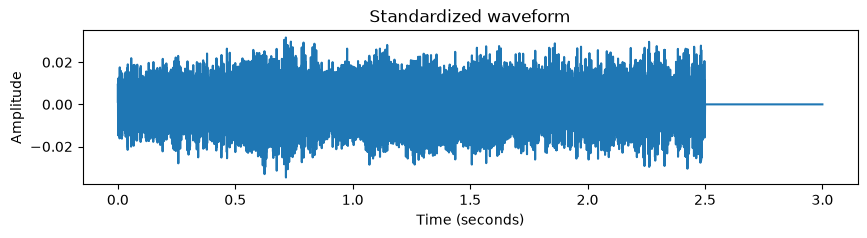

In [228]:
def load_audio(path):
    audio, _ = librosa.load(str(path), sr=SR, mono=True)
    return audio.astype(np.float32)

def fix_length(audio):
    return librosa.util.fix_length(audio, size=SAMPLES)

example = load_audio(next(POS.glob('*.wav')))
print('Original samples:', len(example))
example = fix_length(example)
print('Standardized samples:', len(example))
plt.figure(figsize=(10, 2))
plt.plot(np.arange(len(example)) / SR, example)
plt.xlabel('Time (seconds)')
plt.ylabel('Amplitude')
plt.title('Standardized waveform')
plt.show()

In [ ]:
def make_spectrogram(audio):
    audio = fix_length(np.asarray(audio, dtype=np.float32))

    mel = librosa.feature.melspectrogram(
        y=audio, sr=SR, n_fft=N_FFT,
        hop_length=HOP, n_mels=N_MELS,
        center=False, power=2.0
    )
    mel_db = librosa.power_to_db(mel, ref=1.0)
    # Fixed scaling across training/inference; do not re-normalize clips individually.
    mel_db = np.clip(mel_db, -80.0, 20.0)
    scaled = (mel_db + 80.0) / 100.0
    return scaled.T[..., np.newaxis].astype(np.float32)

    return scaled.T[..., np.newaxis].astype(np.float32)


## Build Mel Spectrogram

CNN input shape: (184, 128, 1)


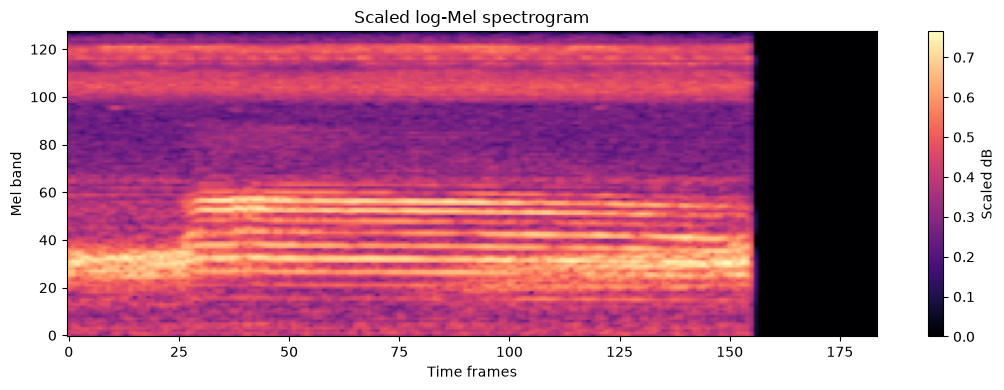

In [230]:
sample_spec = make_spectrogram(example)
print("CNN input shape:", sample_spec.shape)
plt.figure(figsize=(11, 4))
plt.imshow(sample_spec[:, :, 0].T, origin="lower", aspect="auto", cmap="magma")
plt.xlabel("Time frames")
plt.ylabel("Mel band")
plt.title("Scaled log-Mel spectrogram")
plt.colorbar(label="Scaled dB")
plt.tight_layout()
plt.show()

In [232]:
positive_files = sorted(POS.glob('*.wav'))
negative_files = sorted(NEG.glob('*.wav'))
if not positive_files or not negative_files:
    raise ValueError('Need WAV files in both positive and negative folders.')

files = positive_files + negative_files
y = np.array([1] * len(positive_files) + [0] * len(negative_files), dtype=np.float32)

X = np.stack([make_spectrogram(load_audio(p)) for p in files])

In [233]:
print('Spectrograms:', X.shape, 'Labels:', y.shape)
print('Positive:', int(y.sum()), 'Negative:', int(len(y)-y.sum()))

Spectrograms: (810, 184, 128, 1) Labels: (810,)
Positive: 217 Negative: 593


In [234]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)

In [236]:
print('Train:', X_train.shape, 'Val:', X_val.shape, 'Test:', X_test.shape)

Train: (567, 184, 128, 1) Val: (121, 184, 128, 1) Test: (122, 184, 128, 1)


In [237]:
# Step 3: Create TensorFlow datasets
train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train))
val_ds = tf.data.Dataset.from_tensor_slices((X_val, y_val))
test_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test))

# Step 4: Shuffle only training data
train_ds = train_ds.shuffle(
    buffer_size=len(X_train),
    seed=SEED,
    reshuffle_each_iteration=True
)

# Step 5: Batch the datasets
train_ds = train_ds.batch(BATCH_SIZE)
val_ds = val_ds.batch(BATCH_SIZE)
test_ds = test_ds.batch(BATCH_SIZE)

# Step 6: Prefetch
train_ds = train_ds.prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.prefetch(tf.data.AUTOTUNE)
test_ds = test_ds.prefetch(tf.data.AUTOTUNE)


In [240]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=X.shape[1:]),
    tf.keras.layers.Conv2D(16, 3, padding="same", activation='relu'),
    tf.keras.layers.MaxPooling2D(2),
    tf.keras.layers.Conv2D(32, 3, padding="same", activation='relu'),
    tf.keras.layers.MaxPooling2D(2),
    tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu"),
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(1, activation="sigmoid"),

])
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.BinaryCrossentropy(),
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
    ],
)
model.summary()

Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_30 (Conv2D)              │ (None, 184, 128, 16)   │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_30 (MaxPooling2D) │ (None, 92, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_31 (Conv2D)              │ (None, 92, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_31 (MaxPooling2D) │ (None, 46, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_32 (Conv2D)              │ (None, 46, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_13     │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_27 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,521 (107.50 KB)

 Trainable params: 27,521 (107.50 KB)

 Non-trainable params: 0 (0.00 B)

In [242]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2),
]
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=callbacks)

Epoch 1/25


c:\audio\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - accuracy: 0.7055 - loss: 0.6344 - precision: 0.2000 - recall: 0.0329 - val_accuracy: 0.7355 - val_loss: 0.6007 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 0.0010
Epoch 2/25
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - accuracy: 0.7319 - loss: 0.5707 - precision: 0.0000e+00 - recall: 0.0000e+00 - val_accuracy: 0.7355 - val_loss: 0.5240 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 0.0010
Epoch 3/25
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.7319 - loss: 0.5422 - precision: 0.0000e+00 - recall: 0.0000e+00 - val_accuracy: 0.7355 - val_loss: 0.5345 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 0.0010
Epoch 4/25
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.7319 - loss: 0.5049 - precision: 0.0000e+00 - recall: 0.0000e+00 - val_accuracy: 0.7355 - val_loss: 0.5132 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 0.0010
Epoch 5/25
36/36 ━━━━━━

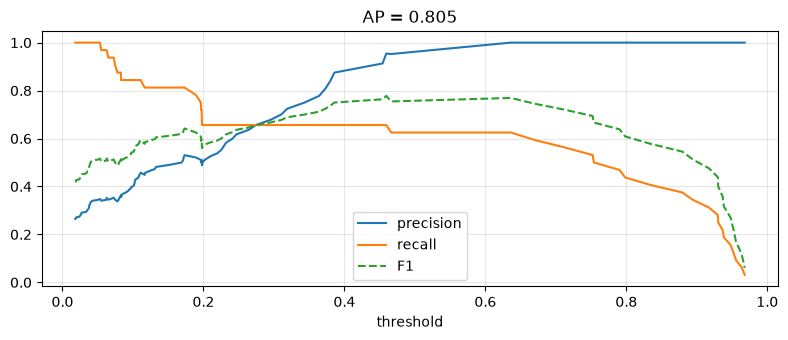

In [264]:
p_val  = model.predict(val_ds,  verbose=0).reshape(-1)
p_test = model.predict(test_ds, verbose=0).reshape(-1)

plot_threshold_curves(y_val, p_val)

In [265]:
t = pick_threshold(y_val, p_val, method="fbeta", beta=1.0, prior=0.05)
print("Chosen threshold:", t)
print("Bootstrap median and 90% range:", bootstrap_threshold(y_val, p_val, method="fbeta", prior=0.05))

Chosen threshold: 0.6361565589904785
Bootstrap median and 90% range: (np.float64(0.6361565589904785), array([0.4594495 , 0.71286094]))


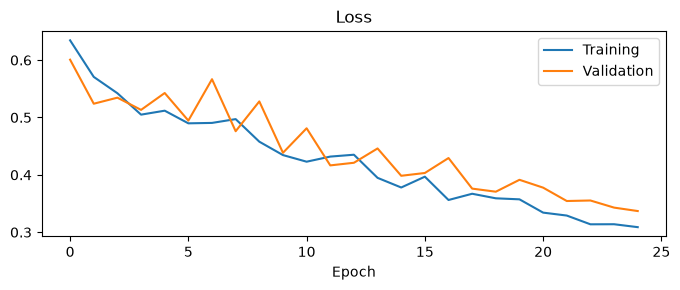

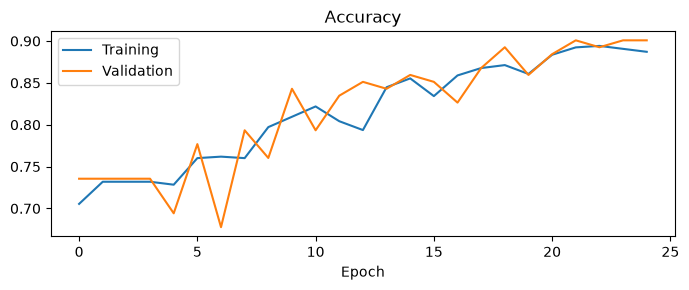

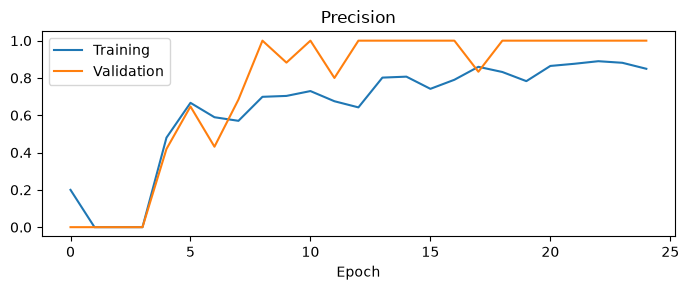

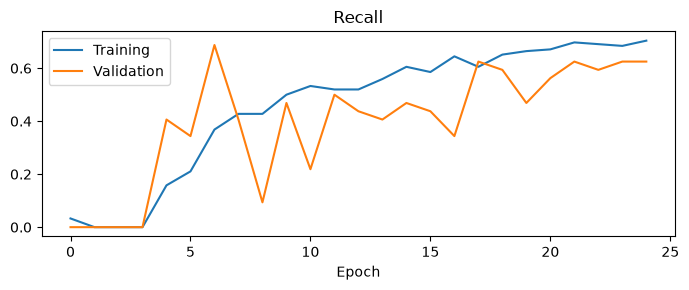

Held-out test metrics:
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9180 - loss: 0.2846 - precision: 0.8966 - recall: 0.7879
{'accuracy': 0.9180327653884888, 'loss': 0.28455811738967896, 'precision': 0.8965517282485962, 'recall': 0.7878788113594055}
              precision    recall  f1-score   support

Not Capuchin       0.88      0.99      0.93        89
    Capuchin       0.95      0.64      0.76        33

    accuracy                           0.89       122
   macro avg       0.92      0.81      0.85       122
weighted avg       0.90      0.89      0.89       122

Confusion matrix:
 [[88  1]
 [12 21]]


In [266]:
for metric in ["loss", "accuracy", "precision", "recall"]:
    plt.figure(figsize=(7, 3))
    plt.plot(history.history[metric], label="Training")
    plt.plot(history.history[f"val_{metric}"], label="Validation")
    plt.title(metric.title())
    plt.xlabel("Epoch")
    plt.legend()
    plt.tight_layout()
    plt.show()

print("Held-out test metrics:")
print(model.evaluate(test_ds, return_dict=True))
probabilities = model.predict(test_ds, verbose=0).reshape(-1)
predicted = (probabilities >= t).astype(int)
print(classification_report(y_test, predicted, target_names=["Not Capuchin", "Capuchin"], zero_division=0))
print("Confusion matrix:\n", confusion_matrix(y_test, predicted))

In [267]:
def predict_clip(path, threshold=t):
    spec = make_spectrogram(load_audio(path))
    probability = float(model.predict(spec[np.newaxis, ...], verbose=0)[0, 0])
    return {"capuchin_probability": probability, "predicted_label": int(probability >= threshold)}

print(predict_clip(positive_files[0]))

{'capuchin_probability': 0.06567485630512238, 'predicted_label': 0}


In [262]:
def recording_windows(audio, window_samples=SAMPLES, stride_samples=SAMPLES):
    """Generate 3-second frames. A short trailing fragment >=1 second is padded."""
    if len(audio) == 0:
        return []
    windows = []
    for start in range(0, len(audio), stride_samples):
        chunk = audio[start:start + window_samples]
        if len(chunk) < SR:  # ignore final fragment shorter than 1 s
            break
        windows.append(fix_length(chunk))
    return windows


def predict_recording(path, threshold=t):
    audio = load_audio(path)  # handles .mp3 and .wav with a compatible audio backend
    windows = recording_windows(audio)
    if not windows:
        return {"recording": Path(path).name, "capuchin_calls": 0,
                "positive_windows": 0, "total_windows": 0}

    specs = np.stack([make_spectrogram(w) for w in windows])
    probabilities = model.predict(specs, batch_size=BATCH_SIZE, verbose=0).reshape(-1)
    detections = (probabilities >= threshold).astype(int)

    # Collapse consecutive positive windows into one approximate detection event.
    estimated_events = sum(int(value) for value, _ in groupby(detections))
    return {"recording": Path(path).name,
            "capuchin_calls": estimated_events,
            "positive_windows": int(detections.sum()),
            "total_windows": len(windows)}

recording_files = sorted(p for p in FOREST.iterdir()
                         if p.suffix.lower() in {".mp3", ".wav", ".flac"}) if FOREST.exists() else []
print(f"Found {len(recording_files)} forest recordings")
if recording_files:
    print(predict_recording(recording_files[0]))

Found 100 forest recordings
{'recording': 'recording_00.mp3', 'capuchin_calls': 5, 'positive_windows': 5, 'total_windows': 60}


In [263]:
results = [predict_recording(path) for path in recording_files]
results_df = pd.DataFrame(results,
    columns=["recording", "capuchin_calls", "positive_windows", "total_windows"])
results_df.to_csv("results.csv", index=False)
print("Saved results.csv")
results_df.head()

Saved results.csv


,recording,capuchin_calls,positive_windows,total_windows
0,recording_00.mp3,5,5,60
1,recording_01.mp3,0,0,60
2,recording_02.mp3,0,0,60
3,recording_03.mp3,0,0,60
4,recording_04.mp3,4,4,60


In [ ]:
model.save("capuchin_audio_classifier.keras")
print("Saved capuchin_audio_classifier.keras")

Saved capuchin_audio_classifier.keras
